<a href="https://colab.research.google.com/github/Martazzz/dropout_rate_academic_success/blob/main/notebooks/01_cleaning_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **01 - Data cleaning and EDA**
---
Predict Students' Dropout and Academic Success project. Phase 0 (data preparation) and phase 1 (EDA).

## Style and palette
---
Common style for the whole project: chart appearance and the order of the categories, so that all the notebooks produce consistent charts.

In [4]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

OUTCOME_ORDER = ["Dropout", "Enrolled", "Graduate"]
OUTCOME_PALETTE = {"Dropout": "#9b4141", "Enrolled": "#b8b8b8", "Graduate": "#298c8c"}
BAR_COLOR = "#0072B2"
DROPOUT_COLOR = "#9b4141"

os.makedirs("figures", exist_ok=True)

ORDER = {
    "Target": OUTCOME_ORDER,
    "Gender": ["Female", "Male"],
    "Displaced": ["No", "Yes"],
    "Debtor": ["No", "Yes"],
    "Tuition_Up_To_Date": ["No", "Yes"],
    "Scholarship_Holder": ["No", "Yes"],
    "Daytime_Evening": ["Daytime", "Evening"],
    "Marital_Group": ["Single", "Not single"],
    "Age_Group": ["17-19", "20-24", "25-29", "30+"],
    "Admission_Grade_Band": ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    "Parent_Education": ["Basic", "Secondary", "Higher", "Unknown"],
    "Application_Order_Group": ["0-1", "2", "3+"],
    "Application_Mode_Group": [
        "General contingent",
        "Over 23 years old",
        "Transfer or change",
        "Prior diploma holder",
        "Special or other",
    ],
    "Passed_None_1st": ["No", "Yes"],
    "Passed_None_2nd": ["No", "Yes"],
}


def apply_order(df):
    df = df.copy()
    for col, cats in ORDER.items():
        if col in df.columns:
            df[col] = pd.Categorical(df[col], categories=cats, ordered=True)
    return df

## Reading the data
---
We load the original data and clean the columns name by removing spaces. Then we select only the useful columns for our ptoject, from the 37 original columns we keep 22.

In [5]:
raw = pd.read_csv("data.csv", sep=";", encoding="utf-8-sig")

raw.columns = raw.columns.str.strip()
print(raw.shape)

RENAME = {
    "Marital status": "Marital_Status",
    "Application mode": "Application_Mode",
    "Application order": "Application_Order",
    "Course": "Course",
    "Daytime/evening attendance": "Daytime_Evening",
    "Previous qualification (grade)": "Prev_Qual_Grade",
    "Mother's qualification": "Mother_Qualification",
    "Father's qualification": "Father_Qualification",
    "Admission grade": "Admission_Grade",
    "Displaced": "Displaced",
    "Debtor": "Debtor",
    "Tuition fees up to date": "Tuition_Up_To_Date",
    "Gender": "Gender",
    "Scholarship holder": "Scholarship_Holder",
    "Age at enrollment": "Age_At_Enrollment",
    "Curricular units 1st sem (enrolled)": "Enrolled_1st",
    "Curricular units 1st sem (approved)": "Approved_1st",
    "Curricular units 1st sem (grade)": "Grade_1st",
    "Curricular units 2nd sem (enrolled)": "Enrolled_2nd",
    "Curricular units 2nd sem (approved)": "Approved_2nd",
    "Curricular units 2nd sem (grade)": "Grade_2nd",
    "Target": "Target",
}

data = raw[list(RENAME)].rename(columns=RENAME).copy()
print(f"{data.shape[0]} rows, {data.shape[1]} columns")

(4424, 37)
4424 rows, 22 columns


## Look at the data and mapping
---
We look at the data to spot missing values, duplicated rows and the distribution of the target. Then we define the dictionaries that transalte the numeric codes into labels (for courses) and groups (for application mode and parents' education level).

In [6]:
data.info()
print("Missing values:", data.isna().sum().sum())
print("Duplicated rows:", data.duplicated().sum())
print(data["Target"].value_counts())

COURSE_NAMES = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening)",
}

APPLICATION_MODE_GROUPS = {
    1: "General contingent",
    17: "General contingent",
    18: "General contingent",
    39: "Over 23 years old",
    42: "Transfer or change",
    43: "Transfer or change",
    51: "Transfer or change",
    57: "Transfer or change",
    7: "Prior diploma holder",
    44: "Prior diploma holder",
    53: "Prior diploma holder",
    2: "Special or other",
    5: "Special or other",
    10: "Special or other",
    15: "Special or other",
    16: "Special or other",
    26: "Special or other",
    27: "Special or other",
}

EDUCATION_LEVEL = {}
for code in [11, 19, 26, 27, 29, 30, 35, 36, 37, 38]:
    EDUCATION_LEVEL[code] = "Basic"
for code in [1, 9, 10, 12, 13, 14, 18, 20, 22, 25, 31, 33, 39]:
    EDUCATION_LEVEL[code] = "Secondary"
for code in [2, 3, 4, 5, 6, 40, 41, 42, 43, 44]:
    EDUCATION_LEVEL[code] = "Higher"
EDUCATION_LEVEL[34] = "Unknown"

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Marital_Status        4424 non-null   int64  
 1   Application_Mode      4424 non-null   int64  
 2   Application_Order     4424 non-null   int64  
 3   Course                4424 non-null   int64  
 4   Daytime_Evening       4424 non-null   int64  
 5   Prev_Qual_Grade       4424 non-null   float64
 6   Mother_Qualification  4424 non-null   int64  
 7   Father_Qualification  4424 non-null   int64  
 8   Admission_Grade       4424 non-null   float64
 9   Displaced             4424 non-null   int64  
 10  Debtor                4424 non-null   int64  
 11  Tuition_Up_To_Date    4424 non-null   int64  
 12  Gender                4424 non-null   int64  
 13  Scholarship_Holder    4424 non-null   int64  
 14  Age_At_Enrollment     4424 non-null   int64  
 15  Enrolled_1st         

## Cleaning the data
---
**Grouping categories:** we replace the numeric codes with labels and group the categories with too many values.

In [7]:
yes_no = {0: "No", 1: "Yes"}

data["Gender"] = data["Gender"].map({0: "Female", 1: "Male"})
for col in ["Displaced", "Debtor", "Tuition_Up_To_Date", "Scholarship_Holder"]:
    data[col] = data[col].map(yes_no)
data["Daytime_Evening"] = data["Daytime_Evening"].map({1: "Daytime", 0: "Evening"})

data["Marital_Group"] = np.where(data["Marital_Status"] == 1, "Single", "Not single")
data["Course_Name"] = data["Course"].map(COURSE_NAMES)
data["Application_Mode_Group"] = data["Application_Mode"].map(APPLICATION_MODE_GROUPS)
data["Application_Order_Group"] = pd.cut(
    data["Application_Order"], bins=[-1, 1, 2, 9], labels=["0-1", "2", "3+"]
)

mother = data["Mother_Qualification"].map(EDUCATION_LEVEL)
father = data["Father_Qualification"].map(EDUCATION_LEVEL)
level = {"Basic": 1, "Secondary": 2, "Higher": 3}
best = np.fmax(mother.map(level), father.map(level))
data["Parent_Education"] = best.map({1: "Basic", 2: "Secondary", 3: "Higher"}).fillna("Unknown")

decoded = ["Gender", "Displaced", "Debtor", "Tuition_Up_To_Date", "Scholarship_Holder",
           "Daytime_Evening", "Course_Name", "Application_Mode_Group", "Application_Order_Group"]

print(data["Parent_Education"].value_counts())
print(pd.crosstab(data["Course_Name"], data["Daytime_Evening"]))

Parent_Education
Basic        2220
Secondary    1311
Higher        793
Unknown       100
Name: count, dtype: int64
Daytime_Evening                       Daytime  Evening
Course_Name                                           
Advertising and Marketing Management      268        0
Agronomy                                  210        0
Animation and Multimedia Design           215        0
Basic Education                           192        0
Biofuel Production Technologies            12        0
Communication Design                      226        0
Equinculture                              141        0
Informatics Engineering                   170        0
Journalism and Communication              331        0
Management                                380        0
Management (evening)                        0      268
Nursing                                   766        0
Oral Hygiene                               86        0
Social Service                            355        0
Socia

---
**Anomalies:** we check for impossible values.

In [8]:
num_check = ["Age_At_Enrollment", "Admission_Grade", "Prev_Qual_Grade",
             "Enrolled_1st", "Approved_1st", "Grade_1st",
             "Enrolled_2nd", "Approved_2nd", "Grade_2nd"]
print(data[num_check].describe().T[["min", "50%", "max"]])

print("Approved > enrolled:",
      (data["Approved_1st"] > data["Enrolled_1st"]).sum() + (data["Approved_2nd"] > data["Enrolled_2nd"]).sum())
print("Admission/previous grades outside 0-200:",
      ((data[["Admission_Grade", "Prev_Qual_Grade"]] < 0) | (data[["Admission_Grade", "Prev_Qual_Grade"]] > 200)).sum().sum())
print("Semester grades outside 0-20:",
      ((data[["Grade_1st", "Grade_2nd"]] < 0) | (data[["Grade_1st", "Grade_2nd"]] > 20)).sum().sum())

for s in ["1st", "2nd"]:
    zero = data[f"Grade_{s}"] == 0
    print(f"{s} semester: grade = 0 for {zero.sum()} students, of which with no unit approved: "
          f"{(zero & (data[f'Approved_{s}'] == 0)).sum()}")

                    min         50%         max
Age_At_Enrollment  17.0   20.000000   70.000000
Admission_Grade    95.0  126.100000  190.000000
Prev_Qual_Grade    95.0  133.100000  190.000000
Enrolled_1st        0.0    6.000000   26.000000
Approved_1st        0.0    5.000000   26.000000
Grade_1st           0.0   12.285714   18.875000
Enrolled_2nd        0.0    6.000000   23.000000
Approved_2nd        0.0    5.000000   20.000000
Grade_2nd           0.0   12.200000   18.571429
Approved > enrolled: 0
Admission/previous grades outside 0-200: 0
Semester grades outside 0-20: 0
1st semester: grade = 0 for 718 students, of which with no unit approved: 718
2nd semester: grade = 0 for 870 students, of which with no unit approved: 870


## Derived variables
---
We create the dropout indicator, the approval rates, the "no units passed" flag, the grade change, the age and admission-grade bands anche the financial risk score. Zero grades become missing values because they mean "no unit passed".



In [9]:
data["Dropout_Binary"] = (data["Target"] == "Dropout").astype(int)

for s in ["1st", "2nd"]:
    enrolled = data[f"Enrolled_{s}"]
    approved = data[f"Approved_{s}"]
    data[f"Passed_None_{s}"] = (approved == 0).map({True: "Yes", False: "No"}).where(enrolled > 0)
    data[f"Approval_Rate_{s}"] = approved / enrolled.where(enrolled > 0)
    data[f"Grade_{s}"] = data[f"Grade_{s}"].where(approved > 0)

data["Grade_Change"] = data["Grade_2nd"] - data["Grade_1st"]

data["Age_Group"] = pd.cut(
    data["Age_At_Enrollment"], bins=[16, 19, 24, 29, 100], labels=ORDER["Age_Group"]
)
data["Admission_Grade_Band"] = pd.qcut(
    data["Admission_Grade"], q=4, labels=ORDER["Admission_Grade_Band"]
)
data["Financial_Risk"] = (
    (data["Debtor"] == "Yes").astype(int)
    + (data["Tuition_Up_To_Date"] == "No").astype(int)
    + (data["Scholarship_Holder"] == "No").astype(int)
)

print(data["Age_Group"].value_counts().sort_index())
print(data.groupby("Admission_Grade_Band", observed=True)["Admission_Grade"].agg(["min", "max", "count"]))
print(data["Financial_Risk"].value_counts().sort_index())
print(data[["Grade_1st", "Grade_2nd", "Approval_Rate_1st", "Approval_Rate_2nd", "Grade_Change"]].isna().sum())

Age_Group
17-19    1952
20-24    1334
25-29     427
30+       711
Name: count, dtype: int64
                        min    max  count
Admission_Grade_Band                     
Q1 (lowest)            95.0  117.9   1111
Q2                    118.0  126.1   1109
Q3                    126.2  134.8   1101
Q4 (highest)          134.9  190.0   1103
Financial_Risk
0     992
1    2731
2     478
3     223
Name: count, dtype: int64
Grade_1st            718
Grade_2nd            870
Approval_Rate_1st    180
Approval_Rate_2nd    180
Grade_Change         912
dtype: int64


## Clean dataset
---
We add 0/1 versions of the binary variables, apply the order to the categories and save the clean dataset.

In [10]:
for col in ["Gender", "Displaced", "Debtor", "Tuition_Up_To_Date", "Scholarship_Holder"]:
    data[col + "_num"] = (data[col] == ORDER[col][1]).astype(int)

data = apply_order(data)

missing = data.isna().sum()
print("Columns with missing values (expected: grades, approval rates, Passed_None, Grade_Change):")
print(missing[missing > 0])
print(data.shape)

OUT_FILE = "student_dropout_cleaned.csv"
data.to_csv(OUT_FILE, index=False)

Columns with missing values (expected: grades, approval rates, Passed_None, Grade_Change):
Grade_1st            718
Grade_2nd            870
Passed_None_1st      180
Approval_Rate_1st    180
Passed_None_2nd      180
Approval_Rate_2nd    180
Grade_Change         912
dtype: int64
(4424, 41)


The remaining missing values are intentional: semester grades are missing when no unit was passed  and approval rates are missing for the 180 students enrolled in no unit.

# Target distribution
---
We count how many students dropped out, gradueted or are still enrolled.

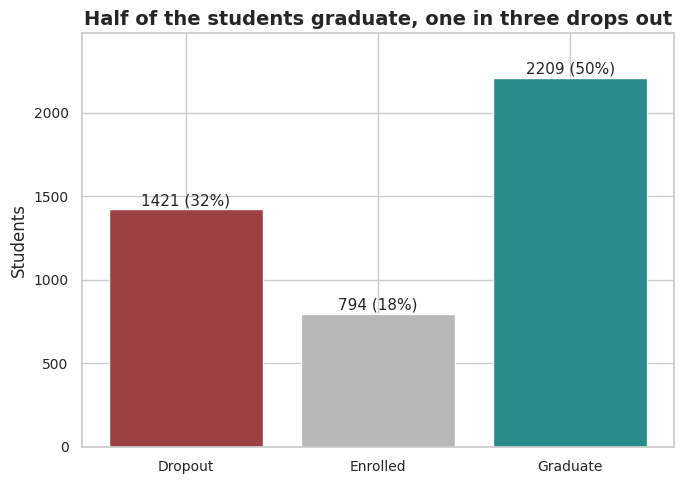

In [11]:
counts = data["Target"].value_counts().reindex(OUTCOME_ORDER)
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(OUTCOME_ORDER, counts.values, color=[OUTCOME_PALETTE[o] for o in OUTCOME_ORDER])
for bar, n, p in zip(bars, counts.values, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 25,
            f"{n} ({p:.0f}%)", ha="center", fontsize=11)
ax.set_ylabel("Students")
ax.set_ylim(0, counts.max() * 1.12)
ax.set_title("Half of the students graduate, one in three drops out")
plt.tight_layout()
plt.savefig("figures/eda_target.png", dpi=200, bbox_inches="tight")
plt.show()

# Categorical data count
---
For each categorical parameter we count the students and visualize the bar plots.

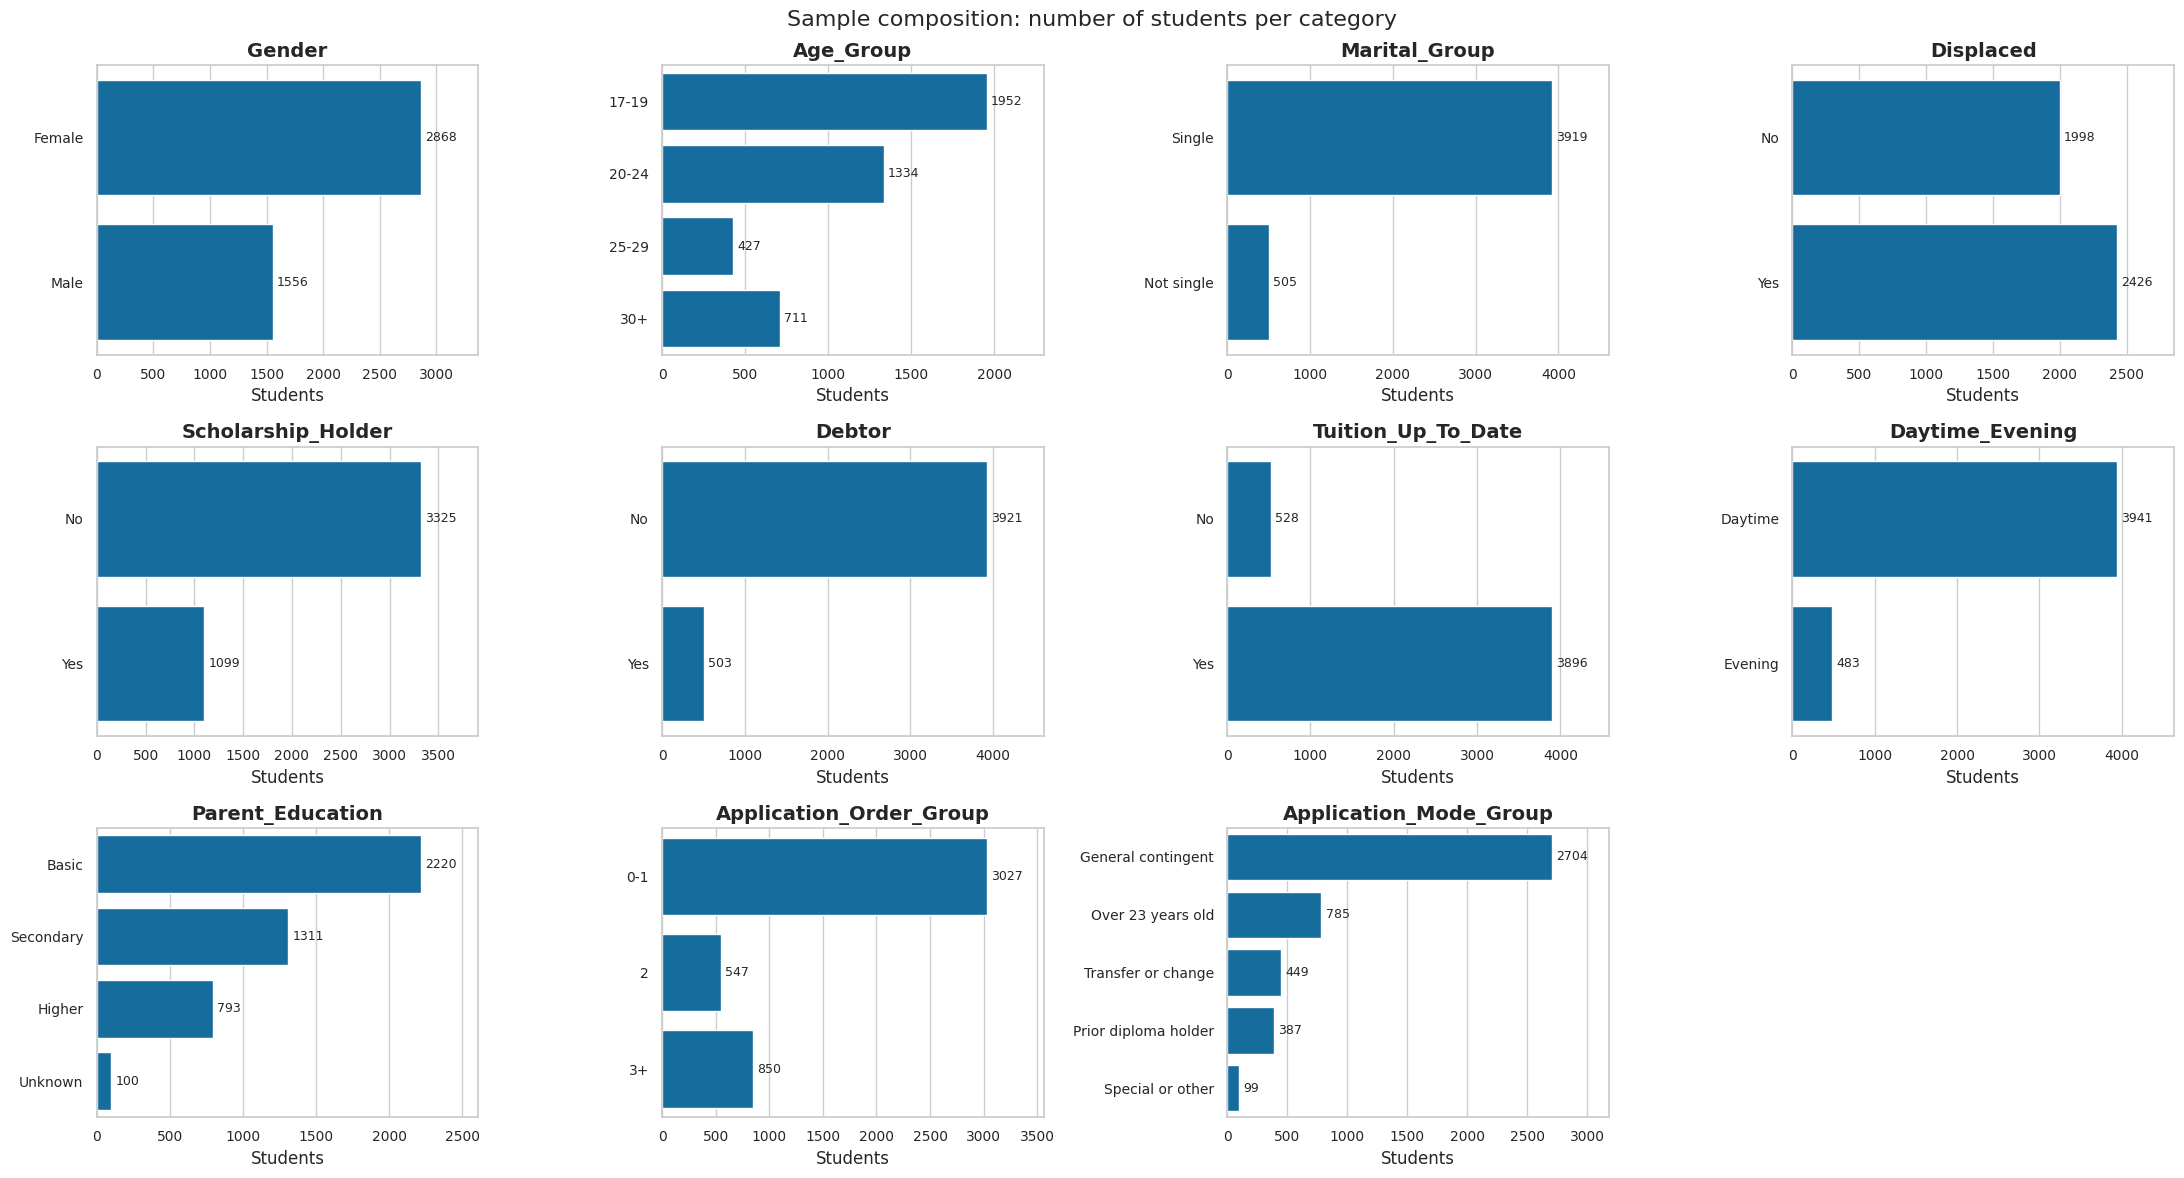

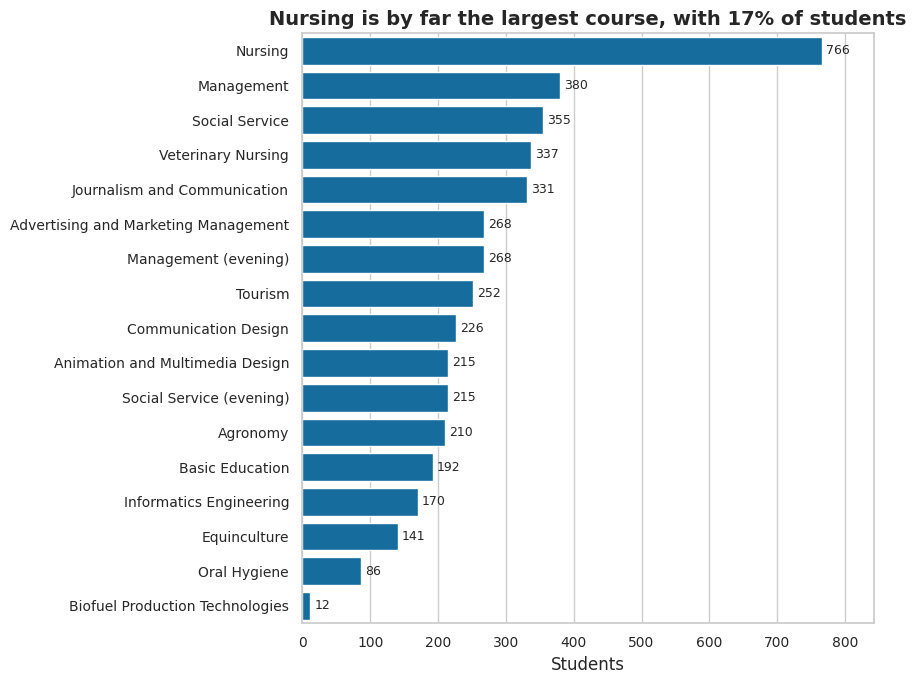

In [12]:
comp_cols = ["Gender", "Age_Group", "Marital_Group", "Displaced", "Scholarship_Holder", "Debtor",
             "Tuition_Up_To_Date", "Daytime_Evening", "Parent_Education",
             "Application_Order_Group", "Application_Mode_Group"]

fig, axes = plt.subplots(3, 4, figsize=(22, 12))
for ax, col in zip(axes.flat, comp_cols):
    sns.countplot(data=data, y=col, color=BAR_COLOR, ax=ax)
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("Students")
    ax.set_ylabel("")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
    ax.grid(axis="y", visible=False)
axes.flat[-1].axis("off")
fig.suptitle("Sample composition: number of students per category", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_composition.png", dpi=200, bbox_inches="tight")
plt.show()

course_counts = data["Course_Name"].value_counts()
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=course_counts.values, y=course_counts.index, color=BAR_COLOR, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
ax.set_xlabel("Students")
ax.set_ylabel("")
ax.set_xlim(0, course_counts.max() * 1.1)
ax.set_title("Nursing is by far the largest course, with 17% of students")
plt.tight_layout()
plt.savefig("figures/eda_courses.png", dpi=200, bbox_inches="tight")
plt.show()

# Numerical data distribution
---
For each numerical parameter we visualize the distribution of its values.

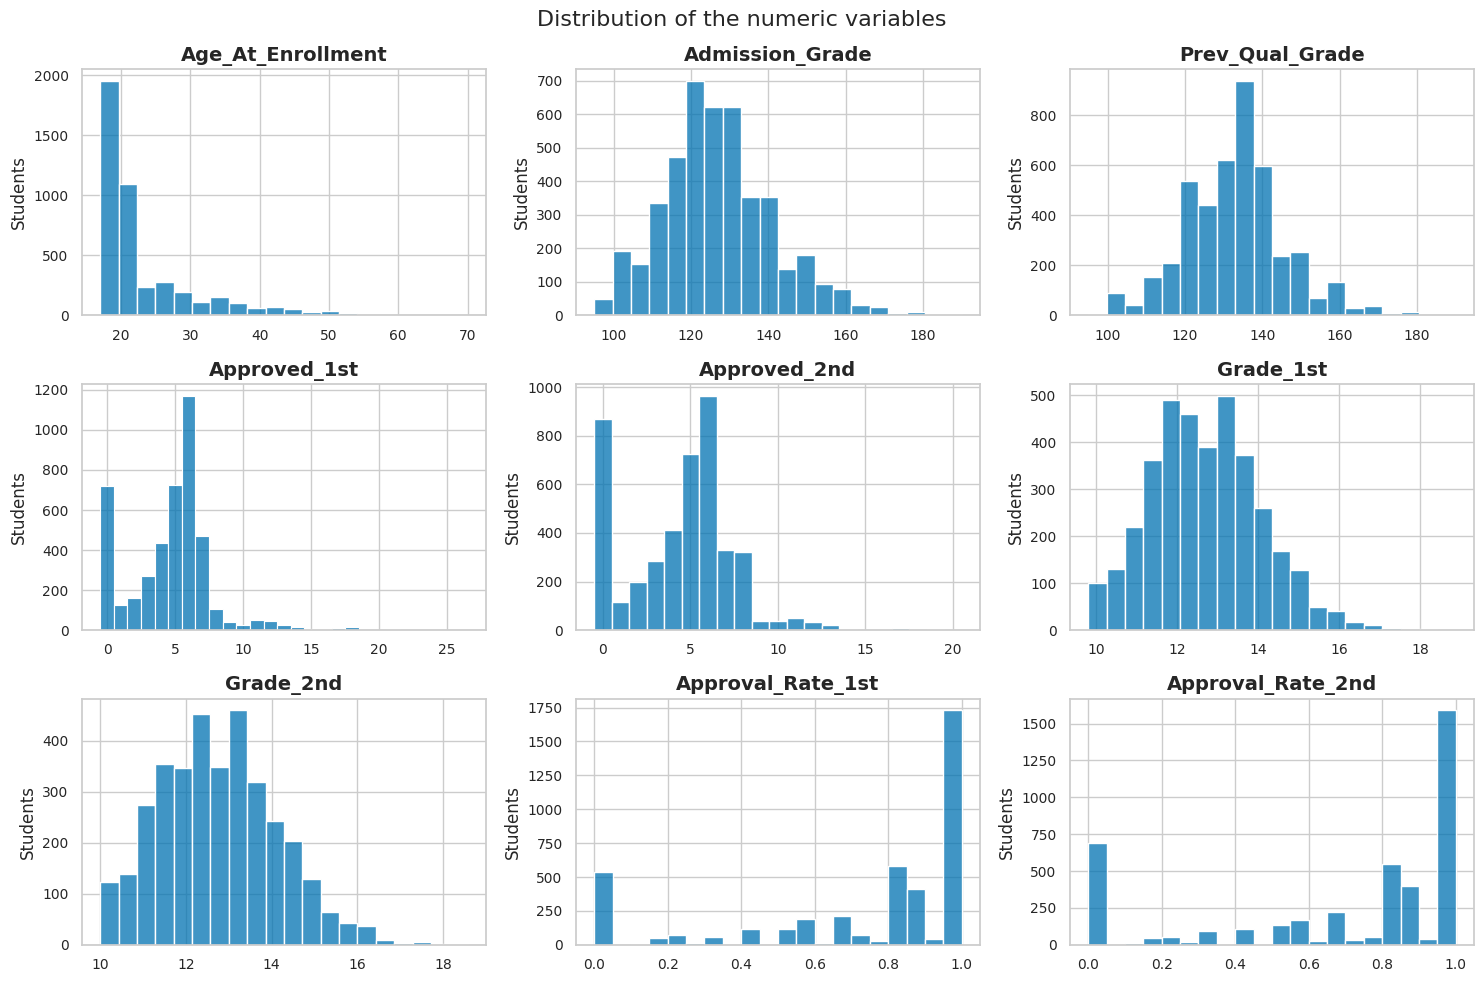

In [13]:
hist_cols = ["Age_At_Enrollment", "Admission_Grade", "Prev_Qual_Grade", "Approved_1st",
             "Approved_2nd", "Grade_1st", "Grade_2nd", "Approval_Rate_1st", "Approval_Rate_2nd"]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, hist_cols):
    sns.histplot(data=data, x=col, bins=20, discrete=data[col].nunique() < 30, color=BAR_COLOR, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Students")
fig.suptitle("Distribution of the numeric variables", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_numeric.png", dpi=200, bbox_inches="tight")
plt.show()

# Dropout rate by category and course
---
We see the correlation between the target (dropout) and the other variables. Then we see the dropout rate based on the different courses.

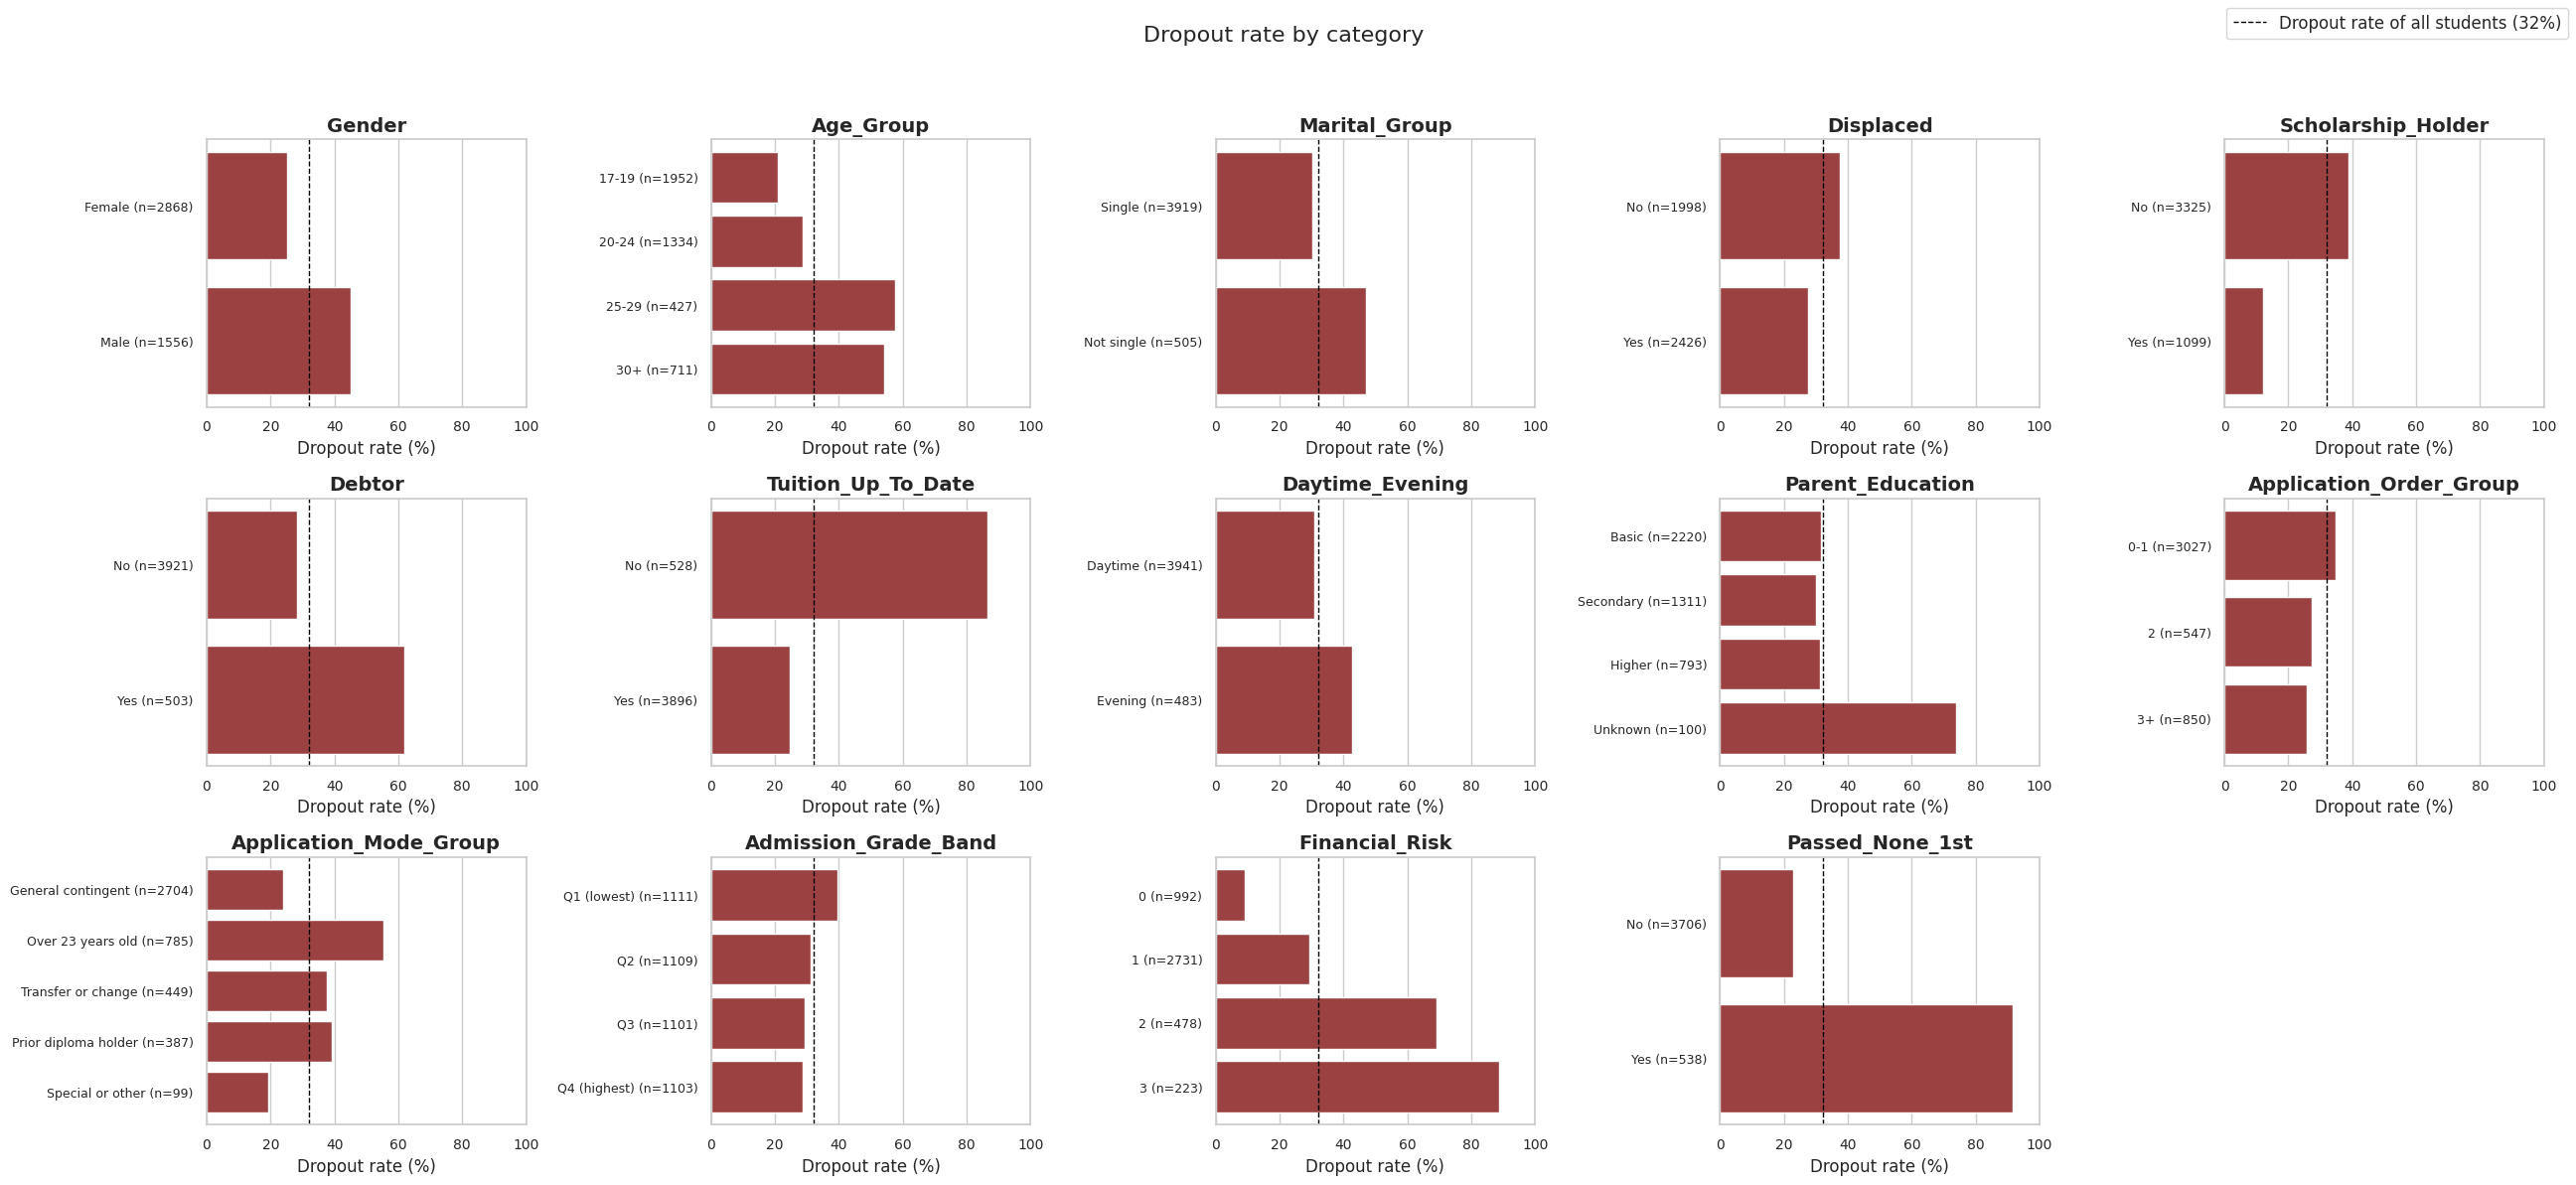

In [14]:
from matplotlib.lines import Line2D

overall = data["Dropout_Binary"].mean() * 100
overall_line = Line2D([0], [0], color="black", linestyle="--", linewidth=1,
                      label=f"Dropout rate of all students ({overall:.0f}%)")


def plot_dropout_rate(ax, col):
    g = data.groupby(col, observed=True)["Dropout_Binary"].agg(["mean", "size"])
    ax.barh(range(len(g)), g["mean"] * 100, color=DROPOUT_COLOR)
    ax.axvline(overall, color="black", linestyle="--", linewidth=1)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"{i} (n={n})" for i, n in zip(g.index, g["size"])], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Dropout rate (%)")
    ax.set_title(col)
    ax.grid(axis="y", visible=False)


rate_cols = comp_cols + ["Admission_Grade_Band", "Financial_Risk", "Passed_None_1st"]

fig, axes = plt.subplots(3, 5, figsize=(26, 12))
for ax, col in zip(axes.flat, rate_cols):
    plot_dropout_rate(ax, col)
axes.flat[-1].axis("off")
fig.suptitle("Dropout rate by category", fontsize=16)
fig.legend(handles=[overall_line], loc="upper right", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("figures/eda_dropout_rate_grid.png", dpi=200, bbox_inches="tight")
plt.show()

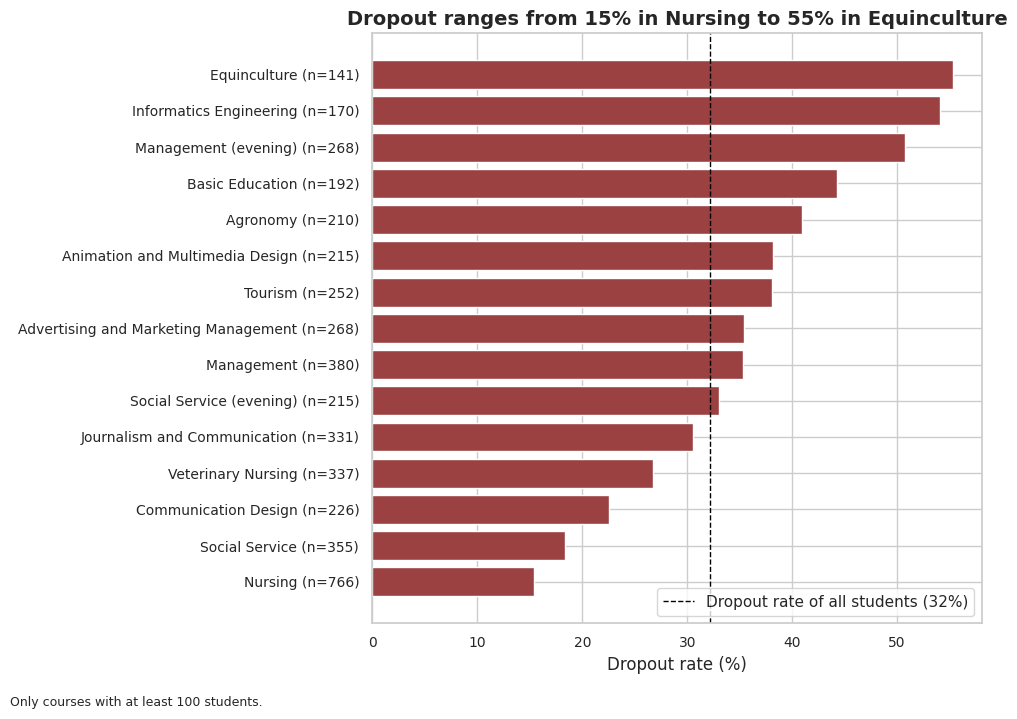

In [15]:
course_rate = data.groupby("Course_Name").agg(rate=("Dropout_Binary", "mean"), n=("Dropout_Binary", "size"))
course_rate = course_rate[course_rate["n"] >= 100].sort_values("rate")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(course_rate)), course_rate["rate"] * 100, color=DROPOUT_COLOR)
ax.axvline(overall, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(course_rate)))
ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(course_rate.index, course_rate["n"])])
ax.set_xlabel("Dropout rate (%)")
ax.set_title("Dropout ranges from 15% in Nursing to 55% in Equinculture")
ax.legend(handles=[overall_line], loc="lower right")
plt.figtext(0.01, -0.02, "Only courses with at least 100 students.", fontsize=9)
plt.tight_layout()
plt.savefig("figures/eda_dropout_by_course.png", dpi=200, bbox_inches="tight")
plt.show()

# Data correlation
---
We consider the numerical parmeters and the numerical version of categorical parameters produced in the `Phase 0` of the project and we see which parameters are correlated using a heatmap.



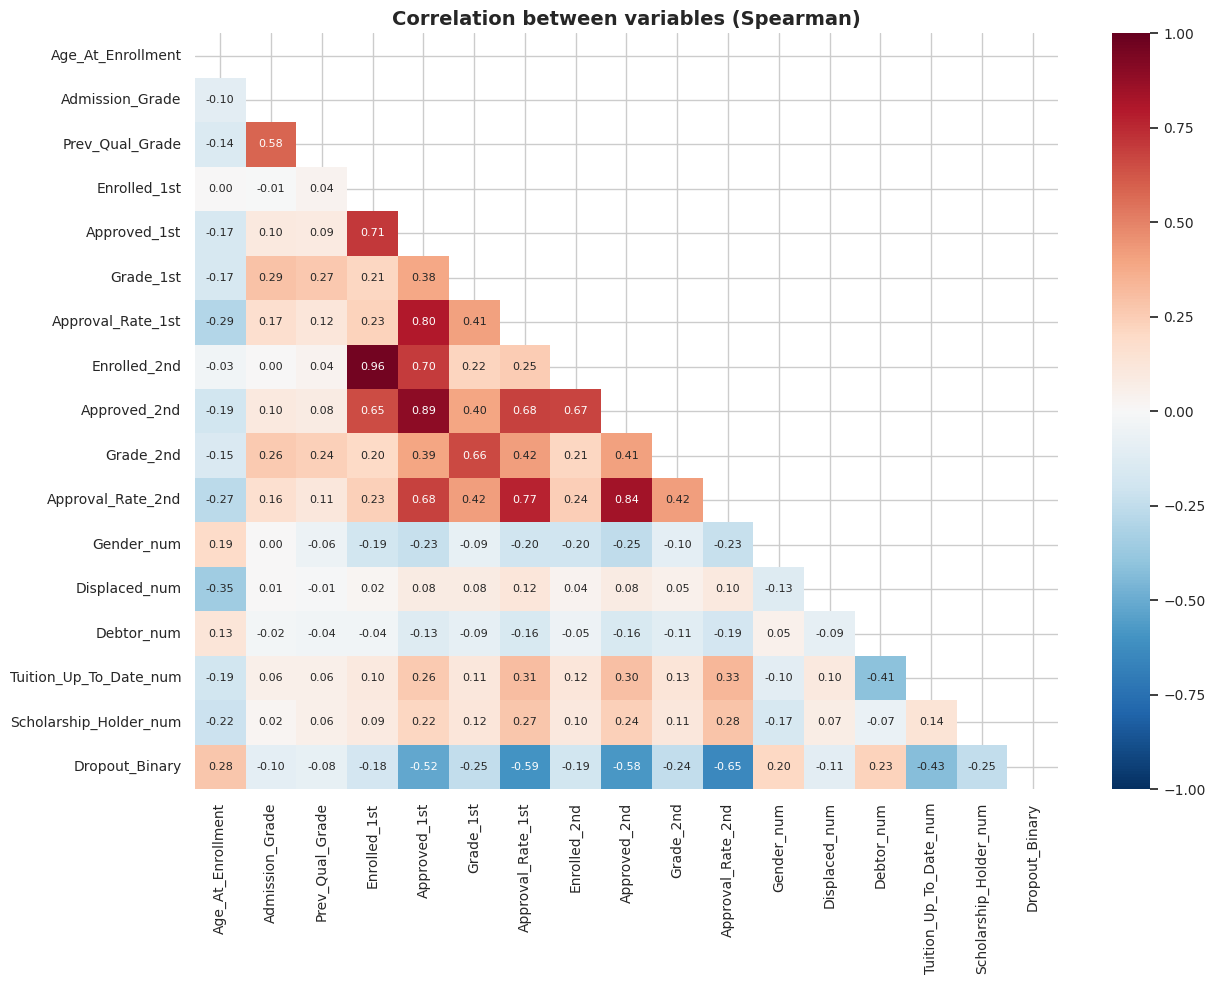

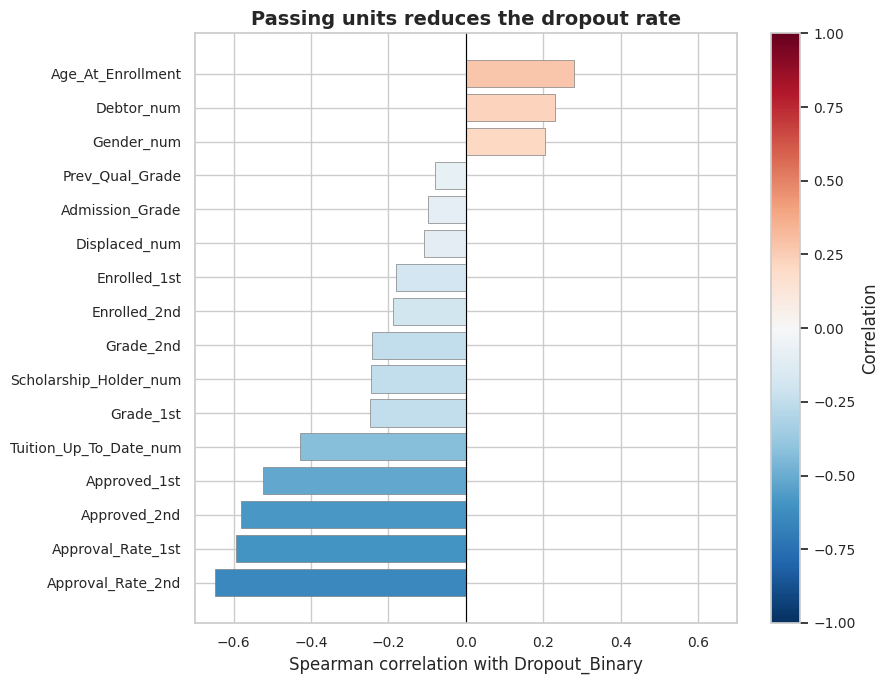

Approval_Rate_2nd        -0.65
Approval_Rate_1st        -0.59
Approved_2nd             -0.58
Approved_1st             -0.52
Tuition_Up_To_Date_num   -0.43
Grade_1st                -0.25
Scholarship_Holder_num   -0.25
Grade_2nd                -0.24
Enrolled_2nd             -0.19
Enrolled_1st             -0.18
Displaced_num            -0.11
Admission_Grade          -0.10
Prev_Qual_Grade          -0.08
Gender_num                0.20
Debtor_num                0.23
Age_At_Enrollment         0.28
Name: Dropout_Binary, dtype: float64


In [16]:
from matplotlib.colors import Normalize

corr_cols = ["Age_At_Enrollment", "Admission_Grade", "Prev_Qual_Grade",
             "Enrolled_1st", "Approved_1st", "Grade_1st", "Approval_Rate_1st",
             "Enrolled_2nd", "Approved_2nd", "Grade_2nd", "Approval_Rate_2nd",
             "Gender_num", "Displaced_num", "Debtor_num", "Tuition_Up_To_Date_num",
             "Scholarship_Holder_num", "Dropout_Binary"]
corr = data[corr_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, annot_kws={"size": 8})
plt.title("Correlation between variables (Spearman)")
plt.tight_layout()
plt.savefig("figures/eda_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

corr_drop = corr["Dropout_Binary"].drop("Dropout_Binary").sort_values()

cmap = plt.get_cmap("RdBu_r")
norm = Normalize(vmin=-1, vmax=1)
limit = round(corr_drop.abs().max() + 0.05, 1)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(corr_drop.index, corr_drop.values, color=cmap(norm(corr_drop.values)),
        edgecolor="gray", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-limit, limit)
ax.set_xlabel("Spearman correlation with Dropout_Binary")
ax.set_title("Passing units reduces the dropout rate")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="Correlation")
plt.tight_layout()
plt.savefig("figures/eda_corr_dropout.png", dpi=200, bbox_inches="tight")
plt.show()
print(corr_drop.round(2))

# Academic results and age by outcome
---
For six variables (approved units and grades in the two semesters, age and admission grade) we draw one boxplot per outcome and princt the median of the group.

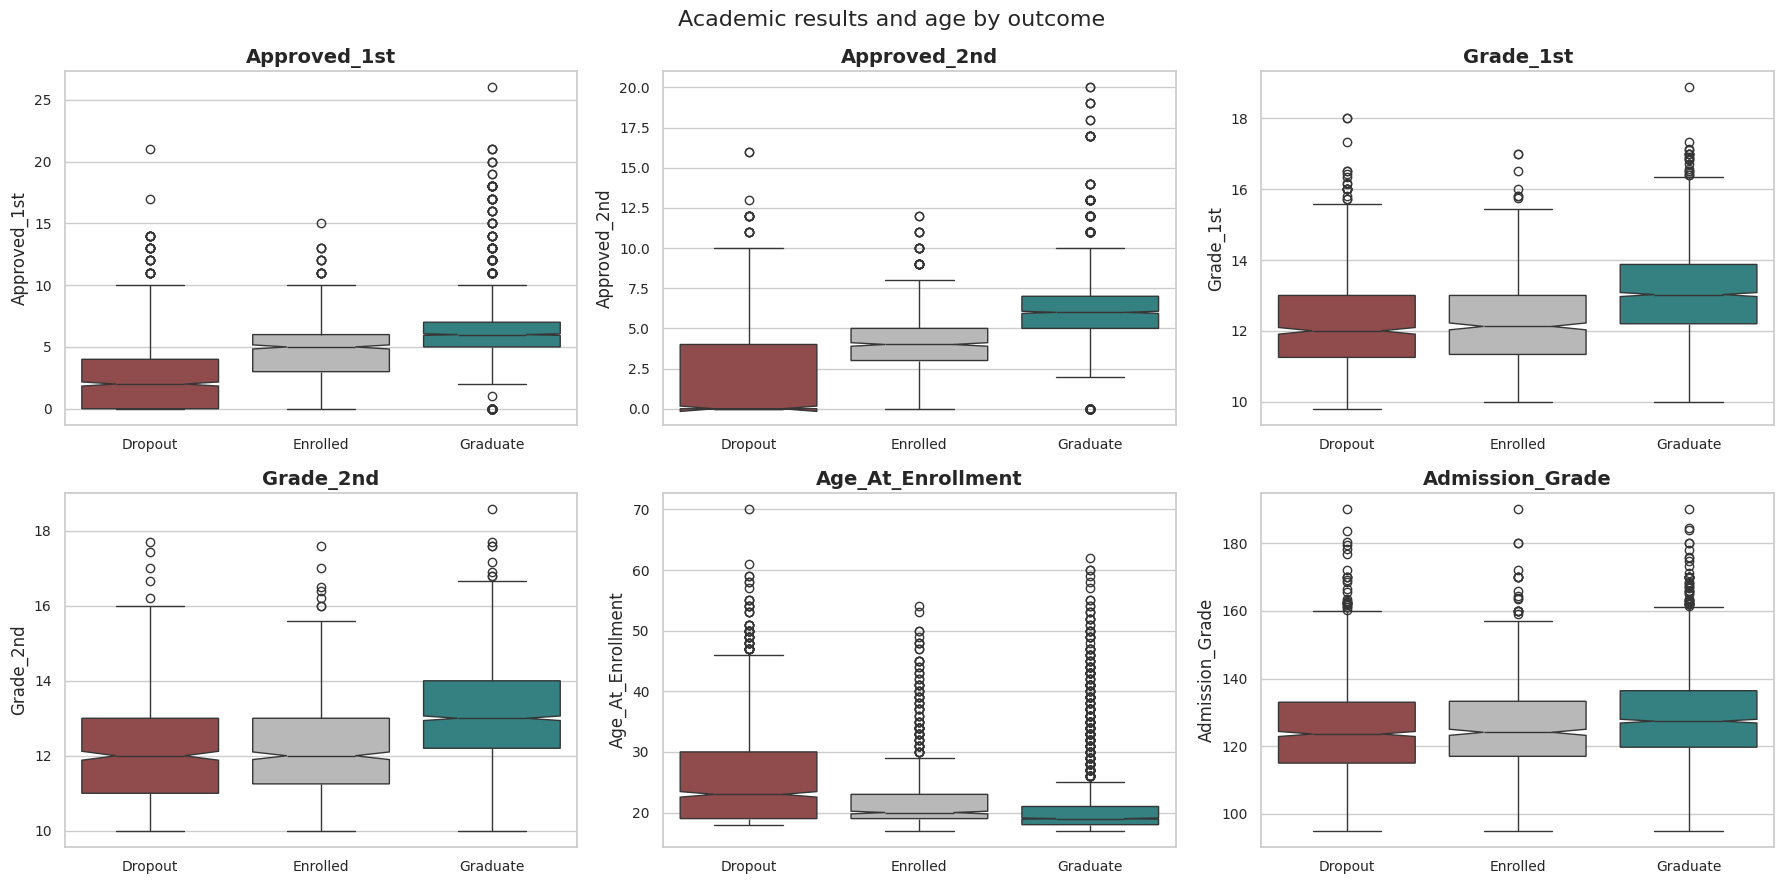

          Approved_1st  Approved_2nd  Grade_1st  Grade_2nd  Age_At_Enrollment  \
Target                                                                          
Dropout            2.0           0.0       12.0       12.0               23.0   
Enrolled           5.0           4.0       12.1       12.0               20.0   
Graduate           6.0           6.0       13.0       13.0               19.0   

          Admission_Grade  
Target                     
Dropout             123.6  
Enrolled            124.1  
Graduate            127.4  


In [18]:
box_cols = ["Approved_1st", "Approved_2nd", "Grade_1st", "Grade_2nd", "Age_At_Enrollment", "Admission_Grade"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, box_cols):
    sns.boxplot(data=data, x="Target", y=col, hue="Target", order=OUTCOME_ORDER,
                palette=OUTCOME_PALETTE, legend=False, ax=ax, notch=True)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Academic results and age by outcome", fontsize=16)
plt.tight_layout()
plt.savefig("figures/eda_boxplots_by_outcome.png", dpi=200, bbox_inches="tight")
plt.show()

print(data.groupby("Target", observed=True)[box_cols].median().round(1))